In [1]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import seaborn as sns
import matplotlib.pyplot as plt


### Question 1

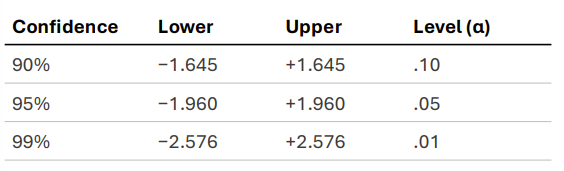

In [2]:
x_bar = 52
s = 10
n = 100

std_error = np.sqrt(s**2 / n)
print(f'estimated standard error x_bar: {std_error}')

estimated standard error x_bar: 1.0


In [3]:
z_stat  = (x_bar - 50) / std_error
z_stat

np.float64(2.0)

z-stat of 2 shows that the null is 2 standard devitions away from observed mean. Means we will find significance at 1.645*std_error and 1.96*std_error, but not at 2.576*std_error, which correspond with alpha = 0.1, 0.05, and 0.01 respectivelly.

In [4]:
lower_90 = x_bar - 1.645 * std_error
upper_90 = x_bar + 1.645 * std_error
lower_95 = x_bar - 1.96 * std_error
upper_95 = x_bar + 1.96 * std_error
lower_99 = x_bar - 2.576 * std_error
upper_99 = x_bar + 2.576 * std_error
print(f'90% ci: ({lower_90}, {upper_90})')
print(f'95% ci: ({lower_95}, {upper_95})')
print(f'99% ci: ({lower_99}, {upper_99})')

90% ci: (50.355, 53.645)
95% ci: (50.04, 53.96)
99% ci: (49.424, 54.576)


We are 95% confident that the population parameter is between 50.04 and 53.96. We have sufficient evidence to reject the null hypothesis x = 50 at alpha = 0.1 and 0.05, but not at alpha = 0.01.

### Question 2

In [5]:
x_bar = 11.5
s = 3
n = 36

std_error = np.sqrt(s**2 / n)
print(f'estimated std error: {std_error}')


estimated std error: 0.5


In [6]:
lower_95 = x_bar - 1.96 * std_error
upper_95 = x_bar + 1.96 * std_error
print(f'95% ci: ({lower_95}, {upper_95})')

95% ci: (10.52, 12.48)


In [7]:
null = 12

z = (x_bar - null) / std_error
p = 2 * norm.cdf(-abs(z))
print(f'p-value: {p}')

p-value: 0.31731050786291415


* We are 95% confident that the true population X is between 10.52 and 12.48, therefore we fail to reject the null hypothesis that mu = 12 at alpha = 0.05. 
* Because the p-value of 0.317 is higher than alpha = 0.05, we fail to reject the null hypothesis. 

* Both approaches show that we do not have sufficient evidence to say that 12 is not plausible for the population mean.

### Question 3

In [8]:
x_bar_A = 25
s_A = 8
n_A = 100

x_bar_B = 22
s_B = 7
n_B = 100

std_error_A = np.sqrt(s_A**2 / (n_A))
std_error_B = np.sqrt(s_B**2 / (n_B))

difference = x_bar_A - x_bar_B
std_error_gap = np.sqrt(std_error_A**2 + std_error_B**2)

In [9]:
lower_95_gap = difference - 1.96 * std_error_gap
upper_95_gap = difference + 1.96 * std_error_gap
print(f'95% ci gap (A - B): ({lower_95_gap}, {upper_95_gap})')

95% ci gap (A - B): (0.9164914207040087, 5.083508579295991)


In [10]:
z = (difference - 0) / std_error_gap
p = 2 * norm.cdf(-abs(z))
print(f'p-value: {p}')
print(f'z-statistic: {z}')

p-value: 0.00477009846556243
z-statistic: 2.8221626051507918


* From the confidence interval: we are 95% confident that the true gap is between 0.9165 and 5.083. At alpha = 0.05, this is sufficient to reject the null hypothesis.
* From the z-statistic: Becuase the z-statistic of 2.82 exceeds the critical value of 1.96 at alpha = 0.05, we reject null. Evidence to suggest h_A.
* From the p-value: because the p-value of 0.00477 is less than alpha = 0.05, we reject the null hypothesis. There is evidence to suggest that X_A is different from X_B.


### Question 4

In [11]:
ames_prices = pd.read_csv('./data/ames_prices.csv')
ames_prices['indicator'] = (ames_prices['Central.Air'] == 'Y').astype(int)

part a

In [24]:
R = 2000
seed = 123
rng = np.random.default_rng(seed)
point_estimate = ames_prices['indicator'].mean()


sample_estimates = []
for r in range(R):
    sample = ames_prices.sample(frac=1, replace=True, random_state=rng)
    sample_estimate = sample['indicator'].mean()
    sample_estimates.append(sample_estimate)
sample_estimates = np.array(sample_estimates)
print(point_estimate)



0.9331058020477816


seed = 123, R = 2000

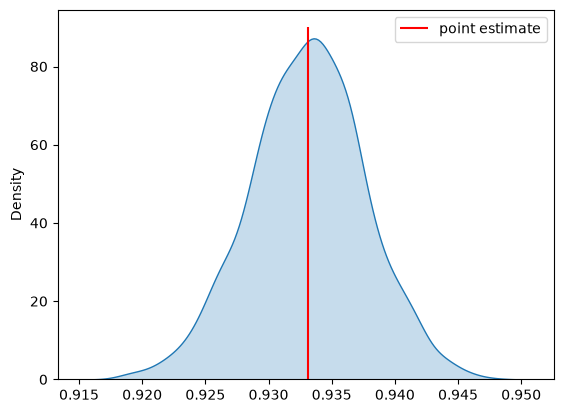

In [25]:
# GUT CHECK PLOT
sns.kdeplot(sample_estimates, fill=True)
plt.vlines(point_estimate, ymin=0, ymax = 90, color='red', label='point estimate')
plt.legend()
plt.show()

part b

In [26]:
mean = sample_estimates.mean()
std_error = np.sqrt(
    ((sample_estimates - sample_estimates.mean())**2).sum() 
    / (len(sample_estimates)-1))

print(f'Standard error: {std_error}')

Standard error: 0.0045711071969300925


part c

In [22]:


ci_90_lower = mean - 1.645 * std_error
ci_90_upper = mean + 1.645 * std_error
ci_95_lower = mean - 1.96 * std_error
ci_95_upper = mean + 1.96 * std_error
ci_99_lower = mean - 2.576 * std_error
ci_99_upper = mean + 2.576 * std_error
print(f'90% ci: ({ci_90_lower}, {ci_90_upper})')
print(f'95% ci: ({ci_95_lower}, {ci_95_upper})')
print(f'99% ci: ({ci_99_lower}, {ci_99_upper})')

90% ci: (0.925536842654224, 0.940575785332124)
95% ci: (0.924096943887191, 0.942015684099157)
99% ci: (0.9212811418538821, 0.9448314861324659)


part d

In [23]:
z = (mean - 0.9) / std_error
p = 2 * norm.cdf(-abs(z))
print(f'z-statistic: {z}')
print(f'p-value: {p}')

z-statistic: 7.231577070731193
p-value: 4.774170254662482e-13


part e

* z-statistic, p-value agree to reject null. Null value not in any confidence interval.

part f

* estimate: Point estimate shows that 0.933 of houses have central air.
* interval: (Note: Using the most restrictive ci for this interpretation). We are 99% confident that the true proportion of homes with central air is between 0.921 and 0.945.
* tests:
    * Because the z-statistic of 7.232 is greater than the critical z (1.645 @ alpha = 0.1, 1.96 @ alpha = 0.05, 2.576 @ alpha = 0.01), reject null hypothesis. There is evidence to suggest that true proportion of houses with central air is different from 0.9.
    * Because the p-value of 4.77x10^-13 is less than alpha = 0.1, 0.05, 0.01, we reject the null hypothesis. There is evidence to suggest that the true proportion of houses with central air is different from 0.9.

### Question 5

In [27]:
ames_prices

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition,indicator
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,1
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,1
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,1
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,1
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,1003,142500,80,RL,37.0,7937,Pave,NaN,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,1
2926,2927,923276100,902,131000,20,RL,NaN,8885,Pave,NaN,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,1
2927,2928,923400125,970,132000,85,RL,62.0,10441,Pave,NaN,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,1
2928,2929,924100070,1389,170000,20,RL,77.0,10010,Pave,NaN,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,1


part a

In [28]:
R = 2000
seed = 123
rng = np.random.default_rng(seed)
df_small = ames_prices.copy()[['area', 'price']]
df_small['asinh_area'] = np.arcsinh(df_small['area'])
df_small['asinh_price'] = np.arcsinh(df_small['price'])
point_estimate = np.corrcoef(df_small['asinh_area'], df_small['asinh_price'])[0, 1]


sample_estimates = []
for r in range(R):
    sample = df_small.sample(frac=1, replace=True, random_state=rng)
    sample_estimate = np.corrcoef(sample['asinh_area'], sample['asinh_price'])[0, 1]
    sample_estimates.append(sample_estimate)
sample_estimates = np.array(sample_estimates)

print(f'Point estimate: {point_estimate}')

Point estimate: 0.7231661530091357


R = 2000, seed = 123

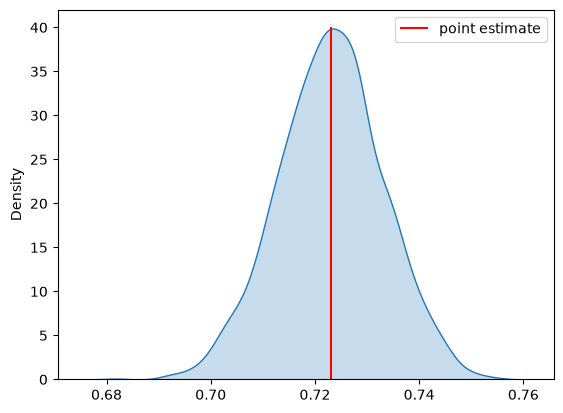

In [29]:
sns.kdeplot(sample_estimates, fill=True)
plt.vlines(point_estimate, ymin=0, ymax = 40, color='red', label='point estimate')
plt.legend()
plt.show()

part b

In [30]:
mean = sample_estimates.mean()

std_error = np.sqrt(((sample_estimates - mean)**2).sum() 
                    / (len(sample_estimates)-1))
print(f'Standard error: {std_error}')

Standard error: 0.010028773013898757


part c

In [31]:
ci_90_lower = mean - 1.645 * std_error
ci_90_upper = mean + 1.645 * std_error
ci_95_lower = mean - 1.96 * std_error
ci_95_upper = mean + 1.96 * std_error
ci_99_lower = mean - 2.576 * std_error
ci_99_upper = mean + 2.576 * std_error
print(f'90% ci: ({ci_90_lower}, {ci_90_upper})')
print(f'95% ci: ({ci_95_lower}, {ci_95_upper})')
print(f'99% ci: ({ci_99_lower}, {ci_99_upper})')

90% ci: (0.7064587349045256, 0.7394533981202526)
95% ci: (0.7032996714051475, 0.7426124616196307)
99% ci: (0.6971219472285859, 0.7487901857961923)


part d

In [32]:
null = 0
z = (mean - null) / std_error
p = 2 * norm.cdf(-abs(z))
print(f'z-statistic: {z}')
print(f'p-value: {p}')

z-statistic: 72.088187209986
p-value: 0.0


part e

Results are nowhere near the null hypothesis value of 0, shown both by all ci's and p-value

part f

* estimate: correlation between arcsinh(area) and arcsinh(price) is about 0.723.
* interval: We are 99% confident that the true correlation is between 0.697 and 0.749.   
* test: because the p-value of 0 is less than alpha = 0.1, 0.05, 0.01, reject the null hypothesis. There is evidence to suggest that the correlation between arcsinh(area) and arcsinh(price) is different from 0.

* Explain what would go wrong if area and price were resampled separately?
    * Correlation would be 0 because the relationship between the variables would not be preserved.


###  Question 6

In [33]:
metabric = pd.read_csv('./data/metabric.csv')
metabric.head()

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


part a

In [34]:
R = 2000
seed = 123
rng = np.random.default_rng(seed)
point_estimate = metabric['Overall Survival (Months)'].mean()


sample_estimates = []
for r in range(R):
    sample = metabric.sample(frac=1, replace=True, random_state=rng)
    sample_estimate = sample['Overall Survival (Months)'].mean()
    sample_estimates.append(sample_estimate)
sample_estimates = np.array(sample_estimates)

print(f'Point estimate: {point_estimate}')

Point estimate: 129.09429138744105


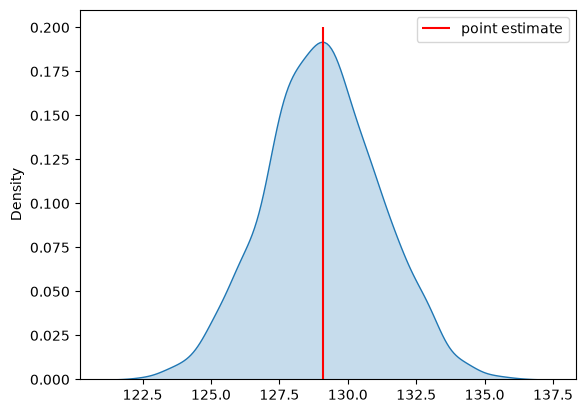

In [35]:
sns.kdeplot(sample_estimates, fill=True)
plt.vlines(point_estimate, ymin=0, ymax = 0.2, color='red', label='point estimate')
plt.legend()
plt.show()

part b

In [36]:
mean = sample_estimates.mean()

std_error = np.sqrt(((sample_estimates - mean)**2).sum() 
                    / (len(sample_estimates)-1))
print(f'Standard error: {std_error}')

Standard error: 2.096102142758481


part c

In [37]:
ci_90_lower = mean - 1.645 * std_error
ci_90_upper = mean + 1.645 * std_error
ci_95_lower = mean - 1.96 * std_error
ci_95_upper = mean + 1.96 * std_error
ci_99_lower = mean - 2.576 * std_error
ci_99_upper = mean + 2.576 * std_error
print(f'90% ci months: ({ci_90_lower}, {ci_90_upper})')
print(f'95% ci months: ({ci_95_lower}, {ci_95_upper})')
print(f'99% ci months: ({ci_99_lower}, {ci_99_upper})')
print(f'90% ci years: ({ci_90_lower/12}, {ci_90_upper/12})')
print(f'95% ci years: ({ci_95_lower/12}, {ci_95_upper/12})')
print(f'99% ci years: ({ci_99_lower/12}, {ci_99_upper/12})')

90% ci months: (125.6236940674929, 132.5198701171683)
95% ci months: (124.96342189252398, 133.18014229213722)
99% ci months: (123.67222297258476, 134.47134121207645)
90% ci years: (10.468641172291075, 11.043322509764025)
95% ci years: (10.413618491043666, 11.098345191011434)
99% ci years: (10.30601858104873, 11.205945101006371)


part d

In [38]:
null = 120
z = (mean - null) / std_error
p = 2 * norm.cdf(-abs(z))
print(f'z-statistic: {z}')
print(f'p-value: {p}')

z-statistic: 4.327929401566326
p-value: 1.5051769655295517e-05


part e

* z-statistic, p-value agree to reject null. Null value not in any confidence interval.

part f

* estimate: Mean survival is about 129 months
* interval: We are 99% confident that the true survival time is between 123.67 and 134.47 months (10.306 and 11.206 years). 
* test: Because the p-value of 1.505x10^-5 is less than alpha = 0.1, 0.05, 0.01, we reject the null hypothesis. There is evidence to suggest that the true suvival is not equal to 120 months. 

* Living patients' eventual death times are right-censored, so this exercise does not estimate unrestricted mean lifetime. This means that our point estimate is even lower than it should be, and that if we had access to unrestricted data we would observe a higher lifetime.

### Question 7

clean data first

In [39]:
# python told me to use the low_memory = False option bc of mixed dtypes
nhanes = pd.read_csv('./data/nhanes_data_17_18.csv', low_memory=False)
nhanes_small = nhanes[['AgeInYearsAtScreening', 'SleepHoursWeekdaysOrWorkdays']].copy()
nhanes_small = nhanes_small.dropna()
nhanes_small = nhanes_small[(nhanes_small['AgeInYearsAtScreening'] >= 18)]
nhanes_small.rename(columns={'AgeInYearsAtScreening': 'age', 'SleepHoursWeekdaysOrWorkdays': 'sleep'}, inplace=True)
nhanes_small.describe()

,age,sleep
count,5489.000000,5489.000000
mean,49.741483,7.621242
std,18.643347,1.677869
min,18.000000,2.000000
25%,33.000000,6.500000
50%,51.000000,7.500000
75%,64.000000,8.500000
max,80.000000,14.000000


part a

In [40]:
R = 2000
seed = 123
rng = np.random.default_rng(seed)
point_estimate = nhanes_small['sleep'].mean()


sample_estimates = []
for r in range(R):
    sample = nhanes_small.sample(frac=1, replace=True, random_state=rng)
    sample_estimate = sample['sleep'].mean()
    sample_estimates.append(sample_estimate)
sample_estimates = np.array(sample_estimates)

print(f'Point estimate: {point_estimate}')

Point estimate: 7.62124248496994


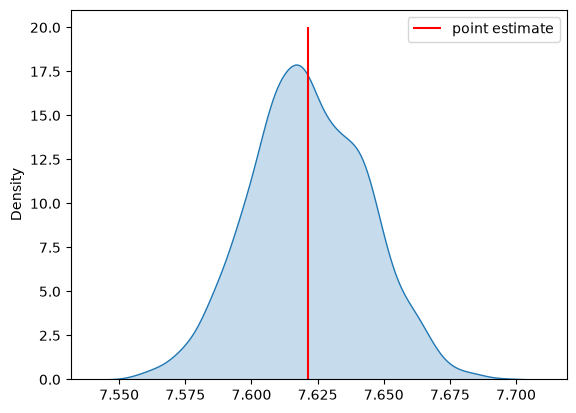

In [41]:
sns.kdeplot(sample_estimates, fill=True)
plt.vlines(point_estimate, ymin=0, ymax = 20, color='red', label='point estimate')
plt.legend()
plt.show()

part b

In [44]:
mean = sample_estimates.mean()

std_error = np.sqrt(((sample_estimates - mean)**2).sum() 
                    / (len(sample_estimates)-1))
print(f'Standard error: {std_error}')

Standard error: 0.021925076984044348


part c

In [45]:


ci_90_lower = mean - 1.645 * std_error
ci_90_upper = mean + 1.645 * std_error
ci_95_lower = mean - 1.96 * std_error
ci_95_upper = mean + 1.96 * std_error
ci_99_lower = mean - 2.576 * std_error
ci_99_upper = mean + 2.576 * std_error
print(f'90% ci: ({ci_90_lower}, {ci_90_upper})')
print(f'95% ci: ({ci_95_lower}, {ci_95_upper})')
print(f'99% ci: ({ci_99_lower}, {ci_99_upper})')

90% ci: (7.585335962881196, 7.657469466158702)
95% ci: (7.5784295636312216, 7.664375865408676)
99% ci: (7.564923716209051, 7.677881712830847)


part d

In [46]:
null = 8
z = (mean - null) / std_error
p = 2 * norm.cdf(-abs(z))
print(f'z-statistic: {z}')
print(f'p-value: {p}')

z-statistic: -17.267774510236375
p-value: 8.225372061791952e-67


part e

* z-statistic, p-value agree to reject null. Null value not in any confidence interval.

part f

* estimate: mean weekday sleep is about 7.62 hours on average for people above 18 with recorded values in the survey
* interval: We are 99% confident that true mean weekday sleep is between 7.565 and 7.678 hours.
* test: Because the p value of 8.22x10^-67 is less than alpha = 0.1, 0.05, 0.01, reject the null hypothesis. There is evidence to suggest that true mean sleep is different from 8 hrs. 

* Results are not nationally representative population estimates. ci's are not survey adjusted.

Statement on AI:
- asked to verify my interpretation of z-score. I wrote the interpretation.
- asked to help troubleshoot how to get random seed to work on the bootstrap to create reproducible sample.